# Q8 e Q9: dinheiro público e propaganda

> **Q8.** Qual a diferença de sucesso entre candidatos que dependem mais de repasses públicos em relação àqueles que são financiados por outras fontes? **[E.P.]**
>
> **Q9.** Onde o candidato investe em propaganda (nuvem de palavras)? **[E.P.]**

**Recorte:** AM, GO, MA, MT, RS e SE, eleições ordinárias de **2018 a 2024** (prestação de contas no leiaute novo). 2026 está no banco, mas fica fora até o TSE publicar o resultado e a prestação final.

Este notebook é o **rascunho da interface**: cada seção é um componente que vai para o painel. O texto com as decisões e as alternativas está em [`docs/q8-q9-publico-propaganda.md`](../docs/q8-q9-publico-propaganda.md).

| Pergunta | Parte | O que mostra | View |
|---|---|---|---|
| Q8 | A | quanto do dinheiro de cada candidato é público (a distribuição) | `q8_faixa` |
| Q8 | B | taxa de eleição: "mais público" × "mais outras fontes", corte em 50% | `q8_taxa` |
| Q8 | C | taxa de eleição faixa a faixa de % público | `q8_faixa` |
| Q8 | D | a conclusão muda com o corte? | `q8_faixa` |
| Q9 | A | quanto foi gasto em cada canal | `q9_canal` |
| Q9 | B | eleitos × não eleitos: a divisão do gasto | `q9_canal` |
| Q9 | C | nuvem de palavras do texto livre, e o valor por trás de cada palavra | `q9_termo` |

**Para rodar do zero:** `uv run scripts/carregar_staging.py` (todos os `sql/*.sql`) e depois *Run All*.

In [1]:
import math
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
# o staging (01_staging) são views que leem os CSV por caminho relativo à raiz
os.chdir(ROOT)
con = duckdb.connect(str(ROOT / "dados" / "processed" / "tse.duckdb"), read_only=True)
SAIDA = ROOT / "output" / "q8_q9"
SAIDA.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 100)


def sql(consulta: str) -> pd.DataFrame:
    return con.sql(consulta).df()


# Cores: as do painel da Q4 (docs/q4-painel), validadas com a skill dataviz
# (validate_palette.js: CVD ΔE 24,7, contraste ≥ 3:1 na superfície clara).
SUPERFICIE = "#fcfcfb"
TEXTO, TEXTO_2, GRADE = "#11161d", "#52514e", "#e4e3df"
PUBLICO, OUTRAS = "#2a78d6", "#eb6834"  # os dois grupos da Q8
FRACO = "#b7d3f6"  # barra com poucos candidatos
SERIE = "#2a78d6"  # série única (Q9)

plt.rcParams.update(
    {
        "figure.facecolor": SUPERFICIE,
        "axes.facecolor": SUPERFICIE,
        "savefig.facecolor": SUPERFICIE,
        "axes.edgecolor": GRADE,
        "axes.labelcolor": TEXTO_2,
        "xtick.color": TEXTO_2,
        "ytick.color": TEXTO_2,
        "text.color": TEXTO,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
        "figure.dpi": 110,
    }
)

CANAL_NOME = {
    "IMPRESSO": "Impresso",
    "RUA": "Rua",
    "RADIO E TV": "Rádio e TV",
    "ADESIVO": "Adesivo",
    "DIGITAL": "Digital",
    "JINGLE": "Jingle",
    "CARRO DE SOM": "Carro de som",
    "JORNAL E REVISTA": "Jornal e revista",
}
CARGOS = ["VEREADOR", "PREFEITO", "DEPUTADO ESTADUAL", "DEPUTADO FEDERAL", "SENADOR", "GOVERNADOR"]
# cada cargo só existe num tipo de eleição: municipal (2020, 2024) ou geral (2018, 2022)
PAINEIS = [(c, a) for c in CARGOS for a in ((2020, 2024) if c in ("VEREADOR", "PREFEITO") else (2018, 2022))]
N_MINIMO = 30  # abaixo disso a taxa é instável: barra clara e o n escrito


def qui_quadrado(e1, n1, e2, n2):
    """Teste qui-quadrado 2×2 (eleito × grupo), sem correção. Devolve (x², p)."""
    tabela = np.array([[e1, n1 - e1], [e2, n2 - e2]], dtype=float)
    esperado = tabela.sum(1, keepdims=True) * tabela.sum(0, keepdims=True) / tabela.sum()
    if (esperado == 0).any():
        return np.nan, np.nan
    x2 = ((tabela - esperado) ** 2 / esperado).sum()
    return x2, math.erfc(math.sqrt(x2 / 2))  # 1 grau de liberdade

## 0. A base está certa?

As checagens de `sql/validacao/q8_q9.sql`. Cada uma deve voltar vazia, salvo as exceções conhecidas anotadas no arquivo:

- **V4:** eleitos sem nenhuma receita declarada (343 vereadores em 2020, 164 em 2024, e poucos casos em outros cargos). Ficam fora da Q8, porque sem receita não há % público.
- **V5:** 12 vereadores do AM em 2020 com R$ 207 milhões cada, de "repasse de partido / outros recursos": erro de digitação na prestação. Ficam na base (não mudam a taxa), mas as **somas de valor** os excluem.
- **V8:** despesas de propaganda sem descrição (2 em 2022, 239 em 2024), que entram no valor por canal mas não na nuvem.

In [2]:
arquivo = ROOT / "sql" / "validacao" / "q8_q9.sql"
# tira os comentários antes de separar as consultas por ";"
texto = "\n".join(
    linha for linha in arquivo.read_text(encoding="utf-8").splitlines() if not linha.lstrip().startswith("--")
)
resultado = []
for consulta in (c for c in texto.split(";") if "SELECT" in c):
    nome = consulta.split("'")[1]
    linhas = con.sql(consulta).fetchall()
    resultado.append({"checagem": nome, "linhas": len(linhas), "situação": "OK" if not linhas else "ver abaixo"})
    if linhas:
        display(pd.DataFrame(linhas).iloc[:, 1:].head(12))
pd.DataFrame(resultado)

,1,2,3
0,2024,VEREADOR,164
1,2024,PREFEITO,2
2,2020,PREFEITO,20
3,2022,DEPUTADO ESTADUAL,1
4,2018,SENADOR,1
5,2020,VEREADOR,343


,1,2,3,4,5
0,2020,AM,VEREADOR,PRISCILA SANTOS DA SILVA,207167006.66
1,2020,AM,VEREADOR,ZELILDE DA SILVA PINHEIRO,207177206.66
2,2020,AM,VEREADOR,INACIO DA SILVA DE OLIVEIRA,207167006.66
3,2020,AM,VEREADOR,JOCINETE BATALHA MORAES,207168606.66
4,2020,AM,VEREADOR,JUSCELINO NUNES BASTOS,207172836.66
5,2020,AM,VEREADOR,TORRICELE PACHECO LINHARES,207167006.66
6,2020,AM,VEREADOR,JORGE BATISTA VERAS,207168556.66
7,2020,AM,VEREADOR,LEIDIANE NASCIMENTO DOS SANTOS,207170006.66
8,2020,AM,VEREADOR,IVO NAZARÉ DO NASCIMENTO,207173527.66
9,2020,AM,VEREADOR,LUIZINHO LELIS DAS CHAGAS,207167006.66


,1,2,3
0,2022,237860,237858
1,2024,607172,606933


,checagem,linhas,situação
0,V1 soma das faixas,0,OK
1,V2 grupo × faixa,0,OK
2,V3 eleitos por UF,0,OK
3,V4 eleito sem receita,6,ver abaixo
4,V5 receita absurda,12,ver abaixo
5,V6 % público fora da faixa,0,OK
6,V7 ano não divulgado,0,OK
7,V8 canal × texto,2,ver abaixo
8,V9 termo inválido,0,OK


In [3]:
sql("""
    SELECT ano, ds_cargo, count(*) AS candidaturas, count(*) FILTER (WHERE fl_eleito) AS eleitos
    FROM q8_candidatura GROUP BY ALL ORDER BY ano, ds_cargo
""").pivot(index="ds_cargo", columns="ano").fillna(0).astype(int)

candidaturas                     eleitos                   
ano                       2018   2020  2022   2024    2018   2020 2022   2024
ds_cargo                                                                     
DEPUTADO ESTADUAL         3119      0  2895      0     210      0  209      0
DEPUTADO FEDERAL          1139      0  1579      0      90      0   90      0
GOVERNADOR                  42      0    48      0       6      0    6      0
PREFEITO                     0   3813     0   3130       0   1229    0   1230
SENADOR                     68      0    45      0      11      0    6      0
VEREADOR                     0  83309     0  71736       0  12457    0  12489

---
# Q8. Quem depende de dinheiro público se elege mais ou menos?

**Dinheiro público** = Fundo Especial de Financiamento de Campanha (FEFC) + Fundo Partidário, qualquer que seja quem repassou (partido ou outro candidato). **Outras fontes** = doação de pessoa física, recursos próprios, financiamento coletivo, caixa do partido fora dos fundos e transferências entre campanhas. A regra está em `sql/02_fonte_recurso.sql`.

Para cada candidato: **% público** = dinheiro público ÷ receita total. Entra só quem foi a voto e declarou alguma receita.

## A. Quanto do dinheiro de cada candidato é público?

Antes de dividir em dois grupos, a distribuição. Faixas de 5 pontos, com 0% e 100% exatos separados.

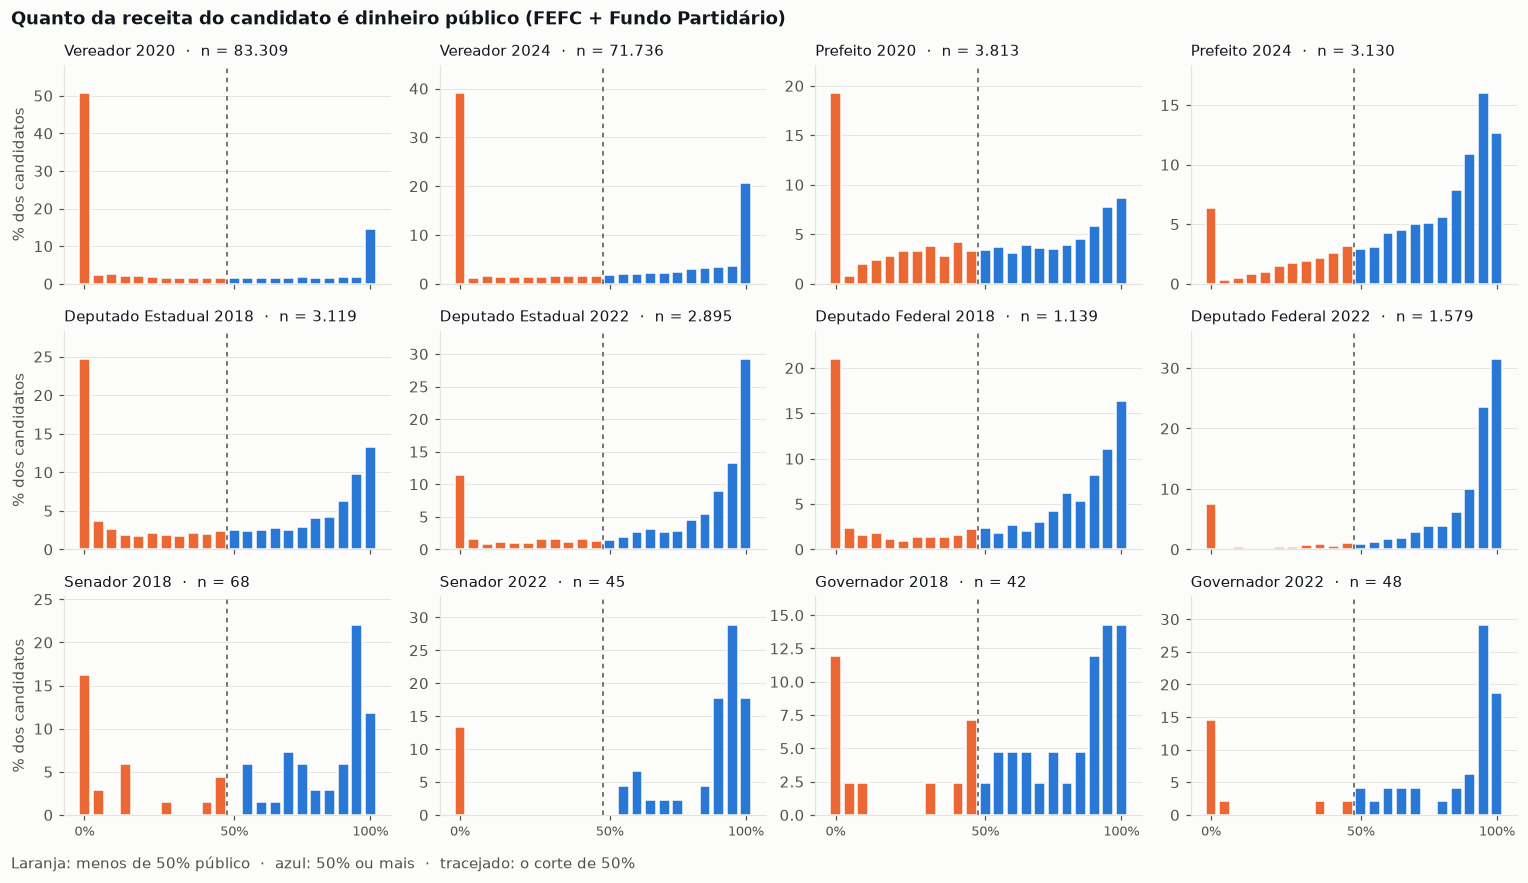

In [4]:
faixa = sql("SELECT * FROM q8_faixa")
por_faixa = faixa.groupby(["ano", "ds_cargo", "nr_faixa", "pc_inicio", "ds_faixa"], as_index=False)[
    ["qt_candidatos", "qt_eleitos"]
].sum()

fig, eixos = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
for ax, (cargo, ano) in zip(eixos.flat, PAINEIS, strict=True):
    d = por_faixa[(por_faixa.ano == ano) & (por_faixa.ds_cargo == cargo)].set_index("nr_faixa")
    n = np.array([d.qt_candidatos.get(f, 0) for f in range(22)])
    pc = 100 * n / n.sum()
    cores = [PUBLICO if f >= 11 else OUTRAS for f in range(22)]
    ax.bar(range(22), pc, width=0.8, color=cores, edgecolor=SUPERFICIE, linewidth=1)
    ax.axvline(10.5, color=TEXTO_2, lw=1, ls=(0, (3, 3)))
    ax.set_title(f"{cargo.title()} {ano}  ·  n = {n.sum():,}".replace(",", "."), loc="left", fontsize=10)
    ax.set_ylim(0, max(pc.max() * 1.15, 10))
    ax.grid(axis="y", color=GRADE, lw=0.6)
    ax.set_axisbelow(True)
for ax in eixos[-1]:
    ax.set_xticks([0, 11, 21], ["0%", "50%", "100%"], fontsize=8.5)
for ax in eixos[:, 0]:
    ax.set_ylabel("% dos candidatos")
fig.suptitle(
    "Quanto da receita do candidato é dinheiro público (FEFC + Fundo Partidário)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.text(
    0.01, 0.005, "Laranja: menos de 50% público  ·  azul: 50% ou mais  ·  tracejado: o corte de 50%", color=TEXTO_2
)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(SAIDA / "q8_a_distribuicao.png", bbox_inches="tight")
plt.show()

In [5]:
# mediana e os extremos, por cargo e ano: o corte de 50% cai em lugares muito diferentes
sql("""
    SELECT ano, ds_cargo,
           round(median(pc_publico), 1) AS mediana_pc_publico,
           round(100.0 * count(*) FILTER (WHERE nr_faixa = 0) / count(*), 1) AS pc_zero_publico,
           round(100.0 * count(*) FILTER (WHERE nr_faixa = 21) / count(*), 1) AS pc_cem_publico,
           round(100.0 * count(*) FILTER (WHERE tp_dependencia = 'MAIS PUBLICO') / count(*), 1) AS pc_mais_publico
    FROM q8_candidatura GROUP BY ALL ORDER BY ds_cargo, ano
""")

,ano,ds_cargo,mediana_pc_publico,pc_zero_publico,pc_cem_publico,pc_mais_publico
0,2018,DEPUTADO ESTADUAL,57.0,24.7,13.3,53.3
1,2022,DEPUTADO ESTADUAL,90.7,11.5,29.2,75.8
2,2018,DEPUTADO FEDERAL,76.5,21.0,16.3,63.4
3,2022,DEPUTADO FEDERAL,96.5,7.5,31.5,87.5
4,2018,GOVERNADOR,77.0,11.9,14.3,71.4
5,2022,GOVERNADOR,91.6,14.6,18.8,79.2
6,2020,PREFEITO,53.1,19.2,8.7,52.0
7,2024,PREFEITO,82.5,6.4,12.7,78.0
8,2018,SENADOR,76.1,16.2,11.8,67.6
9,2022,SENADOR,93.6,13.3,17.8,86.7


**Como ler:** cada painel soma 100% dos candidatos daquele cargo e ano. As duas barras das pontas são quem teve **0%** e **100%** de dinheiro público.

- **Vereador** é bimodal: um bloco grande com 0% público (o partido não repassou nada de fundo) e outro com 100%. Em 2020, metade dos vereadores não recebeu nenhum real público.
- **Deputados, senador e governador (2022)**: quase todos acima de 50%. Depois de 2018 o FEFC virou a principal fonte das campanhas estaduais e federais.
- Consequência para a interface: o corte de 50% separa grupos de tamanhos muito diferentes conforme o cargo. Em deputado federal 2022, "mais outras fontes" são só 13% dos candidatos.

## B. Taxa de eleição: "mais público" × "mais outras fontes"

Corte em 50%. **Taxa de eleição** = eleitos ÷ candidatos do grupo, sempre **dentro do cargo** (vereador e deputado federal têm taxas gerais muito diferentes, e misturar cargos cria diferença falsa). O teste qui-quadrado diz se a diferença entre os dois grupos é maior que o acaso.

In [6]:
taxa = sql("SELECT * FROM q8_taxa")
grupos = taxa.groupby(["ano", "ds_cargo", "tp_dependencia"], as_index=False)[["qt_candidatos", "qt_eleitos"]].sum()
linhas = []
for cargo, ano in PAINEIS:
    g = grupos[(grupos.ano == ano) & (grupos.ds_cargo == cargo)].set_index("tp_dependencia")
    pub = g.loc["MAIS PUBLICO"] if "MAIS PUBLICO" in g.index else pd.Series({"qt_candidatos": 0, "qt_eleitos": 0})
    out = (
        g.loc["MAIS OUTRAS FONTES"]
        if "MAIS OUTRAS FONTES" in g.index
        else pd.Series({"qt_candidatos": 0, "qt_eleitos": 0})
    )
    x2, p = qui_quadrado(pub.qt_eleitos, pub.qt_candidatos, out.qt_eleitos, out.qt_candidatos)
    linhas.append(
        {
            "ano": ano,
            "cargo": cargo,
            "público: eleitos/cand.": f"{int(pub.qt_eleitos)}/{int(pub.qt_candidatos)}",
            "taxa público %": round(100 * pub.qt_eleitos / pub.qt_candidatos, 1) if pub.qt_candidatos else np.nan,
            "outras: eleitos/cand.": f"{int(out.qt_eleitos)}/{int(out.qt_candidatos)}",
            "taxa outras %": round(100 * out.qt_eleitos / out.qt_candidatos, 1) if out.qt_candidatos else np.nan,
            "p (qui²)": p,
        }
    )
tabela_b = pd.DataFrame(linhas)
tabela_b["diferença (p.p.)"] = (tabela_b["taxa público %"] - tabela_b["taxa outras %"]).round(1)
tabela_b.style.format(
    {"taxa público %": "{:.1f}", "taxa outras %": "{:.1f}", "diferença (p.p.)": "{:+.1f}", "p (qui²)": "{:.1e}"},
    na_rep="—",
)

,ano,cargo,público: eleitos/cand.,taxa público %,outras: eleitos/cand.,taxa outras %,p (qui²),diferença (p.p.)
0,2020,VEREADOR,1553/25456,6.1,10904/57853,18.8,0.0e+00,-12.7
1,2024,VEREADOR,4687/33411,14.0,7802/38325,20.4,3.7e-110,-6.4
2,2020,PREFEITO,515/1981,26.0,714/1832,39.0,1.1e-17,-13.0
3,2024,PREFEITO,945/2440,38.7,285/690,41.3,2.2e-01,-2.6
4,2018,DEPUTADO ESTADUAL,75/1663,4.5,135/1456,9.3,1.2e-07,-4.8
5,2022,DEPUTADO ESTADUAL,113/2195,5.1,96/700,13.7,2.4e-14,-8.6
6,2018,DEPUTADO FEDERAL,73/722,10.1,17/417,4.1,2.8e-04,+6.0
7,2022,DEPUTADO FEDERAL,78/1381,5.6,12/198,6.1,8.1e-01,-0.5
8,2018,SENADOR,8/46,17.4,3/22,13.6,6.9e-01,+3.8
9,2022,SENADOR,6/39,15.4,0/6,0.0,3.0e-01,+15.4


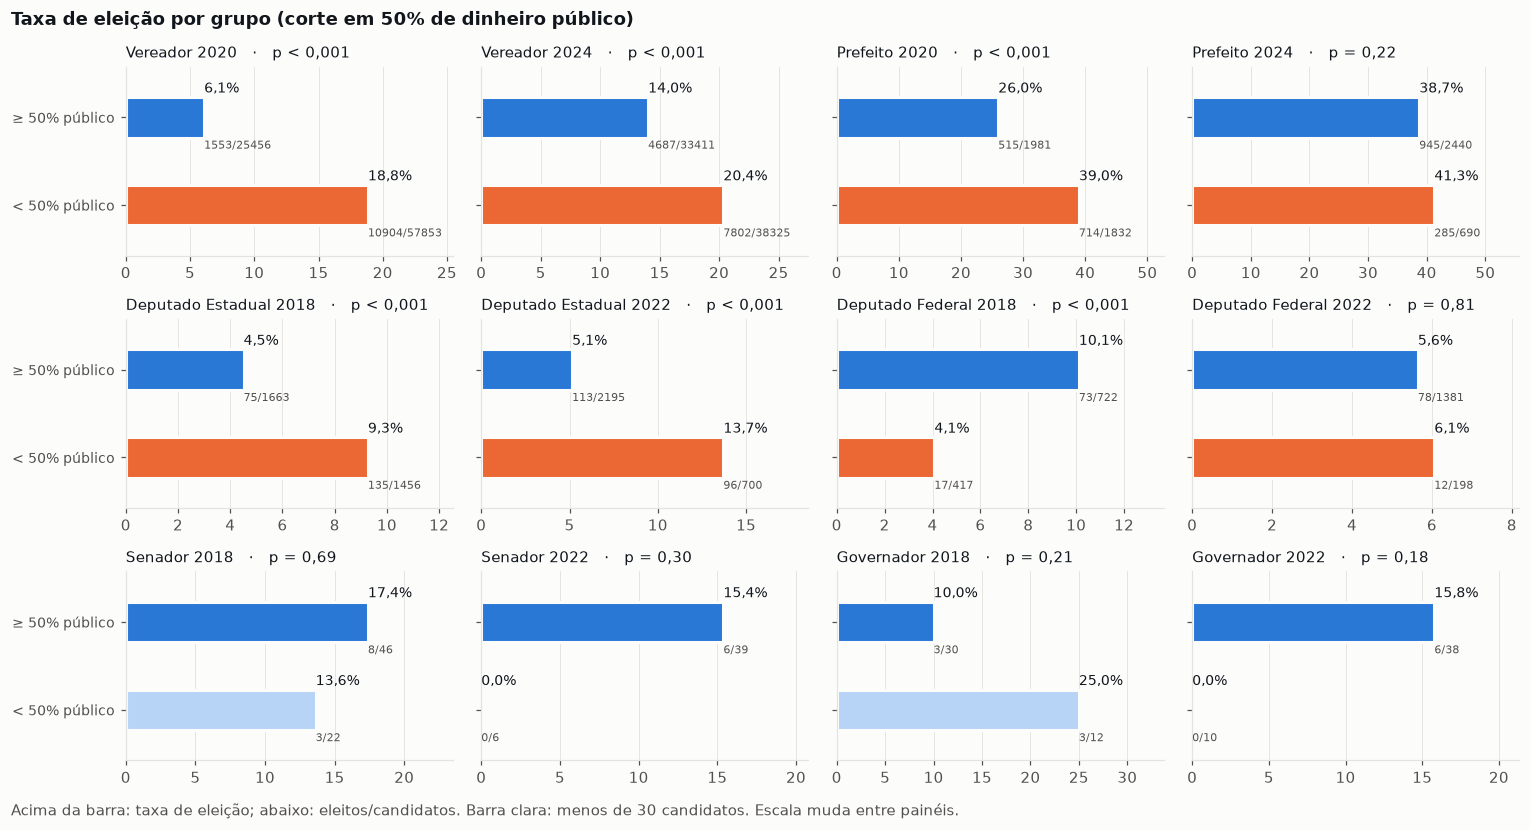

In [7]:
fig, eixos = plt.subplots(3, 4, figsize=(14, 7.5), sharey=True)
for ax, (cargo, ano) in zip(eixos.flat, PAINEIS, strict=True):
    g = grupos[(grupos.ano == ano) & (grupos.ds_cargo == cargo)].set_index("tp_dependencia")
    y = [1.3, 0]
    nomes = ["MAIS PUBLICO", "MAIS OUTRAS FONTES"]
    for yi, nome, cor in zip(y, nomes, [PUBLICO, OUTRAS], strict=True):
        n = int(g.qt_candidatos.get(nome, 0))
        e = int(g.qt_eleitos.get(nome, 0))
        t = 100 * e / n if n else 0
        ax.barh(yi, t, height=0.6, color=cor if n >= N_MINIMO else FRACO, edgecolor=SUPERFICIE, linewidth=2)
        ax.text(t, yi + 0.42, f"{t:.1f}%".replace(".", ","), va="center", fontsize=9, color=TEXTO)
        ax.text(t, yi - 0.42, f"{e}/{n}", va="center", fontsize=7.5, color=TEXTO_2)
    lim = max(
        100
        * (grupos[(grupos.ano == ano) & (grupos.ds_cargo == cargo)].eval("qt_eleitos / qt_candidatos")).max()
        * 1.35,
        5,
    )
    ax.set_xlim(0, lim)
    ax.set_ylim(-0.75, 2.05)
    ax.set_yticks(y, ["≥ 50% público", "< 50% público"], fontsize=9)
    p = tabela_b[(tabela_b.ano == ano) & (tabela_b.cargo == cargo)]["p (qui²)"].iloc[0]
    rot_p = "p < 0,001" if p < 0.001 else f"p = {p:.2f}".replace(".", ",")
    ax.set_title(f"{cargo.title()} {ano}   ·   {rot_p}", loc="left", fontsize=10)
    ax.grid(axis="x", color=GRADE, lw=0.6)
    ax.set_axisbelow(True)
fig.suptitle("Taxa de eleição por grupo (corte em 50% de dinheiro público)", x=0.01, ha="left", fontweight="bold")
fig.text(
    0.01,
    0.005,
    "Acima da barra: taxa de eleição; abaixo: eleitos/candidatos. Barra clara: menos de 30 candidatos. "
    "Escala muda entre painéis.",
    color=TEXTO_2,
)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(SAIDA / "q8_b_taxa_grupos.png", bbox_inches="tight")
plt.show()

**Como ler:** compare as duas barras **dentro de cada painel**; a escala muda entre painéis.

O resultado depende do cargo, e até muda de sinal:

- **Vereador** (2020: 6,1% × 18,8%; 2024: 14,0% × 20,4%), **prefeito 2020** (26,0% × 39,0%) e **deputado estadual** (2018: 4,5% × 9,3%; 2022: 5,1% × 13,7%): quem depende mais de dinheiro público se elege **menos**, com p < 0,001.
- **Deputado federal 2018**: o contrário, "mais público" se elege mais que o dobro (10,1% × 4,1%).
- **Prefeito 2024** (p = 0,22) e **deputado federal 2022** (p = 0,81): sem diferença.
- **Senador e governador**: poucos candidatos no grupo "outras fontes" (barras claras); não dá para afirmar nada.

## C. A taxa faixa a faixa

O corte de 50% joga no mesmo grupo quem teve 0% e quem teve 49% de dinheiro público. Aqui a taxa de eleição em cada faixa de 10 pontos, com 0% e 100% exatos à parte. É a resposta mais completa: mostra **onde** a chance muda.

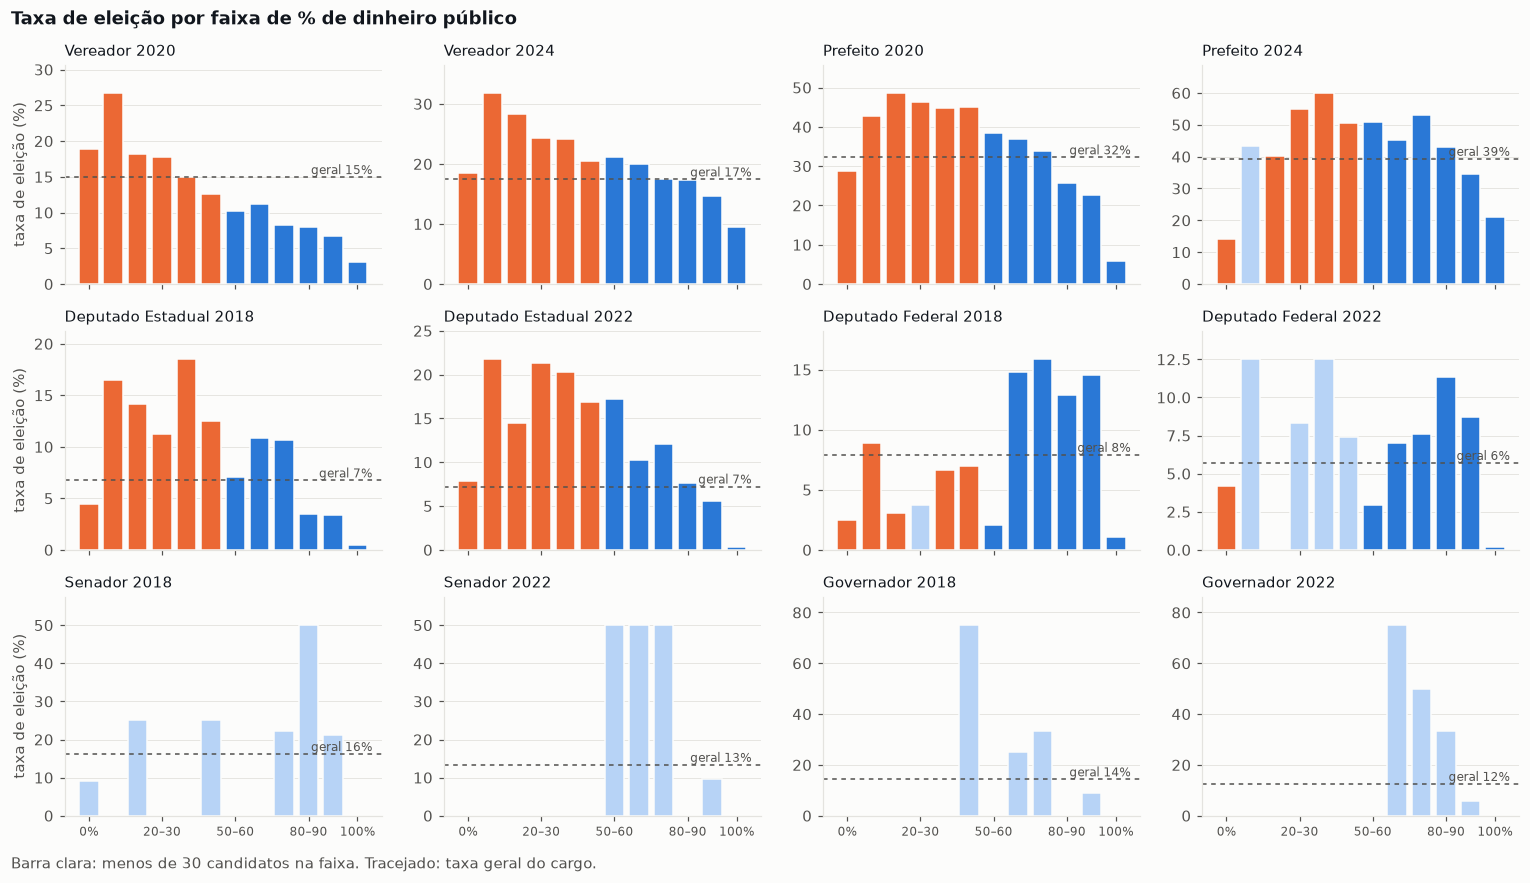

In [8]:
# junta as faixas de 5 pontos em faixas de 10 (as pontas 0% e 100% continuam à parte)
def faixa10(f):
    return 0 if f == 0 else 11 if f == 21 else 1 + (f - 1) // 2


ROTULO10 = ["0%"] + [f"{10 * i}–{10 * (i + 1)}" for i in range(10)] + ["100%"]
por_faixa["f10"] = por_faixa.nr_faixa.map(faixa10)
f10 = por_faixa.groupby(["ano", "ds_cargo", "f10"], as_index=False)[["qt_candidatos", "qt_eleitos"]].sum()

fig, eixos = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
for ax, (cargo, ano) in zip(eixos.flat, PAINEIS, strict=True):
    d = f10[(f10.ano == ano) & (f10.ds_cargo == cargo)].set_index("f10")
    n = np.array([d.qt_candidatos.get(i, 0) for i in range(12)])
    e = np.array([d.qt_eleitos.get(i, 0) for i in range(12)])
    t = np.where(n > 0, 100 * e / np.maximum(n, 1), np.nan)
    cores = [(PUBLICO if i >= 6 else OUTRAS) if n[i] >= N_MINIMO else FRACO for i in range(12)]
    ax.bar(range(12), np.nan_to_num(t), width=0.8, color=cores, edgecolor=SUPERFICIE, linewidth=1)
    geral = 100 * e.sum() / n.sum()
    ax.axhline(geral, color=TEXTO_2, lw=1, ls=(0, (3, 3)))
    ax.text(11.6, geral, f"geral {geral:.0f}%", fontsize=8, color=TEXTO_2, ha="right", va="bottom")
    ax.set_title(f"{cargo.title()} {ano}", loc="left", fontsize=10)
    ax.set_ylim(0, max(np.nanmax(t) * 1.15, 5))
    ax.grid(axis="y", color=GRADE, lw=0.6)
    ax.set_axisbelow(True)
for ax in eixos[-1]:
    ax.set_xticks([0, 3, 6, 9, 11], ["0%", "20–30", "50–60", "80–90", "100%"], fontsize=8)
for ax in eixos[:, 0]:
    ax.set_ylabel("taxa de eleição (%)")
fig.suptitle("Taxa de eleição por faixa de % de dinheiro público", x=0.01, ha="left", fontweight="bold")
fig.text(0.01, 0.005, "Barra clara: menos de 30 candidatos na faixa. Tracejado: taxa geral do cargo.", color=TEXTO_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(SAIDA / "q8_c_taxa_faixa.png", bbox_inches="tight")
plt.show()

In [9]:
tabela_c = f10.assign(
    faixa=lambda d: d.f10.map(dict(enumerate(ROTULO10))),
    taxa=lambda d: (100 * d.qt_eleitos / d.qt_candidatos).round(1),
)
tabela_c[tabela_c.ds_cargo.isin(["VEREADOR", "PREFEITO", "DEPUTADO ESTADUAL", "DEPUTADO FEDERAL"])].pivot_table(
    index=["f10", "faixa"], columns=["ds_cargo", "ano"], values="taxa"
).droplevel(0)

ds_cargo DEPUTADO ESTADUAL       DEPUTADO FEDERAL       PREFEITO        \
ano                   2018  2022             2018  2022     2020  2024   
faixa                                                                    
0%                     4.4   7.8              2.5   4.2     28.8  14.1   
0–10                  16.5  21.7              8.9  12.5     42.9  43.5   
10–20                 14.2  14.5              3.0   0.0     48.5  40.4   
20–30                 11.3  21.3              3.7   8.3     46.5  54.9   
30–40                 18.5  20.3              6.7  12.5     44.8  59.8   
40–50                 12.5  16.9              7.0   7.4     45.1  50.5   
50–60                  7.1  17.2              2.1   2.9     38.5  50.8   
60–70                 10.8  10.2             14.8   7.0     36.9  45.3   
70–80                 10.7  12.0             15.9   7.6     33.9  53.1   
80–90                  3.5   7.6             12.9  11.3     25.6  42.9   
90–100                 3.4   5.6             14.5   8.7     22.7  34.7   
100%                   0.5   0.4              1.1   0.2      5.8  21.2   

ds_cargo VEREADOR        
ano          2020  2024  
faixa                    
0%           18.8  18.5  
0–10         26.7  31.7  
10–20        18.2  28.3  
20–30        17.7  24.3  
30–40        15.0  24.1  
40–50        12.6  20.5  
50–60        10.2  21.2  
60–70        11.2  20.1  
70–80         8.2  17.6  
80–90         8.0  17.2  
90–100        6.7  14.7  
100%          3.1   9.5

**Como ler:** a linha tracejada é a taxa geral do cargo; barra acima dela, faixa que se elege mais que a média.

- **Vereador:** a maior taxa está na faixa de **0 a 10%** público (26,7% em 2020, 31,7% em 2024), e daí a taxa **cai faixa a faixa** até a de 100% (3,1% e 9,5%). Quem tem 0% exato fica abaixo da faixa seguinte (18,8% e 18,5%).
- **Prefeito e deputado estadual:** o mesmo desenho de "morro": sobe da faixa de 0% para as faixas baixas e desce depois.
- **Deputado federal 2018:** o desenho inverso: a taxa salta de menos de 9% abaixo de 60% para 13% a 16% entre 60% e 100%.
- **A faixa de 100% é a pior em quase todo cargo.** São campanhas pequenas: quem só tem dinheiro público teve receita mediana de R$ 3.168 (vereador 2024), contra R$ 5.144 de quem misturou fontes. O dinheiro público, sozinho, não traz a rede de doadores que acompanha uma candidatura competitiva.
- A relação **não é uma reta**, e um corte único esconde isso. É o principal argumento para a interface mostrar as faixas, e não só dois grupos.

## D. A conclusão muda com o corte?

Diferença de taxa (mais público − mais outras fontes), em pontos percentuais, para cada corte possível de 5% a 95%. É a versão estática do **controle deslizante do painel**. Linha acima de zero: "mais público" se elege mais.

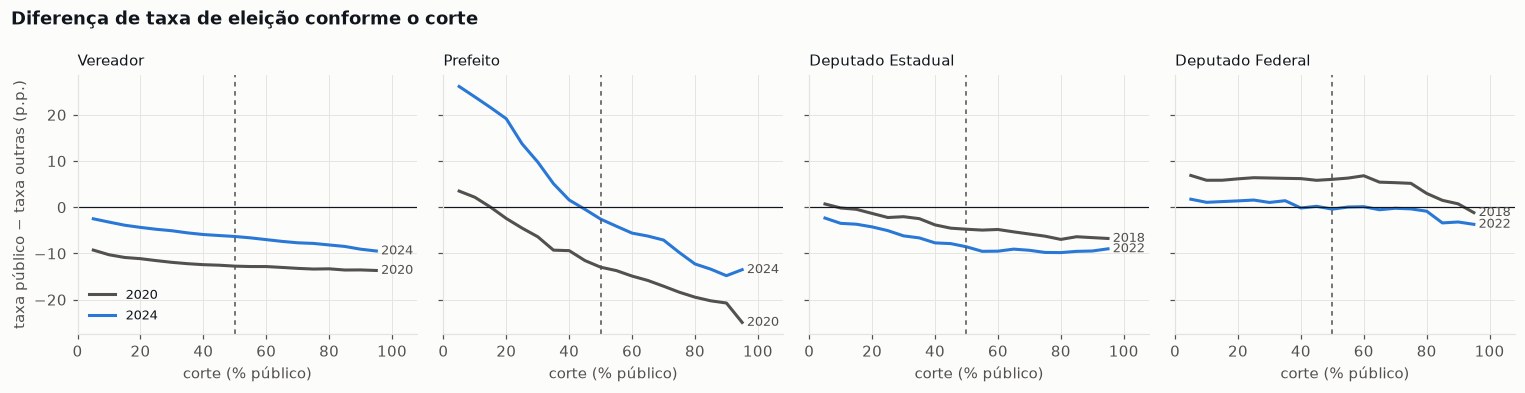

In [10]:
cortes = list(range(5, 100, 5))
sens = []
for cargo, ano in PAINEIS:
    d = por_faixa[(por_faixa.ano == ano) & (por_faixa.ds_cargo == cargo)]
    for c in cortes:
        pub = d[d.pc_inicio >= c]
        out = d[d.pc_inicio < c]
        if pub.qt_candidatos.sum() < N_MINIMO or out.qt_candidatos.sum() < N_MINIMO:
            continue
        sens.append(
            {
                "cargo": cargo,
                "ano": ano,
                "corte": c,
                "dif": 100 * pub.qt_eleitos.sum() / pub.qt_candidatos.sum()
                - 100 * out.qt_eleitos.sum() / out.qt_candidatos.sum(),
            }
        )
sens = pd.DataFrame(sens)

fig, eixos = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, cargo in zip(eixos, ["VEREADOR", "PREFEITO", "DEPUTADO ESTADUAL", "DEPUTADO FEDERAL"], strict=True):
    anos = sorted(sens[sens.cargo == cargo].ano.unique())
    for ano, cor in zip(anos, [TEXTO_2, PUBLICO], strict=True):
        s = sens[(sens.cargo == cargo) & (sens.ano == ano)]
        ax.plot(s.corte, s.dif, color=cor, lw=2, label=str(ano))
        ax.text(s.corte.iloc[-1] + 1.5, s.dif.iloc[-1], str(ano), color=TEXTO_2, fontsize=8.5, va="center")
    ax.axhline(0, color=TEXTO, lw=0.8)
    ax.axvline(50, color=TEXTO_2, lw=1, ls=(0, (3, 3)))
    ax.set_title(cargo.title(), loc="left", fontsize=10)
    ax.set_xlabel("corte (% público)")
    ax.set_xlim(0, 108)
    ax.grid(color=GRADE, lw=0.6)
    ax.set_axisbelow(True)
eixos[0].set_ylabel("taxa público − taxa outras (p.p.)")
eixos[0].legend(frameon=False, fontsize=8.5, loc="lower left")
fig.suptitle("Diferença de taxa de eleição conforme o corte", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(SAIDA / "q8_d_sensibilidade.png", bbox_inches="tight")
plt.show()

In [11]:
# alternativa de corte: a mediana do cargo (grupos do mesmo tamanho)
alt = []
for cargo, ano in PAINEIS[:8]:
    base = sql(f"""
        SELECT fl_eleito, pc_publico >= median(pc_publico) OVER () AS acima
        FROM q8_candidatura WHERE ano = {ano} AND ds_cargo = '{cargo}'
    """)
    a, b = base[base.acima], base[~base.acima]
    x2, p = qui_quadrado(a.fl_eleito.sum(), len(a), b.fl_eleito.sum(), len(b))
    alt.append(
        {
            "cargo": cargo,
            "ano": ano,
            "mediana": sql(f"SELECT median(pc_publico) m FROM q8_candidatura WHERE ano={ano} AND ds_cargo='{cargo}'").m[
                0
            ],
            "taxa ≥ mediana %": round(100 * a.fl_eleito.mean(), 1),
            "taxa < mediana %": round(100 * b.fl_eleito.mean(), 1),
            "p (qui²)": p,
        }
    )
pd.DataFrame(alt).style.format({"p (qui²)": "{:.1e}", "mediana": "{:.1f}"})

,cargo,ano,mediana,taxa ≥ mediana %,taxa < mediana %,p (qui²)
0,VEREADOR,2020,0.0,15.000000,nan,nan
1,VEREADOR,2024,39.2,14.500000,20.300000,3.2e-94
2,PREFEITO,2020,53.0,25.500000,39.000000,4.8e-19
3,PREFEITO,2024,82.5,32.900000,45.700000,2.5e-13
4,DEPUTADO ESTADUAL,2018,57.0,4.300000,9.200000,5.5e-08
5,DEPUTADO ESTADUAL,2022,90.7,2.400000,12.000000,1.6e-23
6,DEPUTADO FEDERAL,2018,76.5,10.400000,5.400000,2.2e-03
7,DEPUTADO FEDERAL,2022,96.5,3.500000,7.900000,2.2e-04


**Como ler:**

- **Vereador e deputado estadual:** a diferença é negativa em praticamente todo corte (prefeito 2020 também, exceto nos cortes de 5% e 10%). A conclusão "quem depende mais de dinheiro público se elege menos" **não depende do corte**, só o tamanho dela.
- **Prefeito 2024:** a linha **cruza o zero** perto de 40%. Com corte baixo, "mais público" se elege mais (+26 p.p. em 5%); com corte alto, menos (−15 p.p. em 90%). Dá para "provar" as duas conclusões escolhendo o corte.
- **Deputado federal:** positivo em 2018 em quase todo corte, perto de zero em 2022.

Por isso o painel deixa o corte nas mãos de quem olha: mostra 50% como padrão e marca a mediana do cargo como referência.

**O que a Q8 não mostra:** que o dinheiro público *causa* derrota ou vitória. O partido decide para quem vai o fundo, e tende a concentrar em quem já tem chance (mandato, nome conhecido). Quem se banca sozinho também é diferente (renda, rede de doadores). É **associação**, dentro do cargo.

---
# Q9. Onde o candidato investe em propaganda?

Duas respostas, porque a **nuvem mostra frequência** (quantas despesas citam a palavra) e a pergunta é sobre **investimento** (valor):

1. **Canal** (A e B): o tipo de despesa que o TSE registra, agrupado em 8 canais (`sql/03_tipo_despesa.sql`). Responde *quanto*.
2. **Palavras** (C): o texto livre que o candidato escreveu na prestação (`ds_despesa`). Responde *o quê*: "santinho", "bandeira", "impulsionamento".

Base: despesas **contratadas** de propaganda, 2018–2024, mesmos cargos da Q8.

## A. Quanto foi gasto em cada canal

In [12]:
canal = sql("SELECT * FROM q9_canal")
CANAIS = (
    canal.groupby("ds_canal").vr_despesa.sum().sort_values(ascending=False).index.tolist()
)  # ordem fixa: do maior ao menor valor no período todo
tot = canal.groupby(["ano", "ds_cargo", "ds_canal"], as_index=False)["vr_despesa"].sum()
tot["pc"] = 100 * tot.vr_despesa / tot.groupby(["ano", "ds_cargo"]).vr_despesa.transform("sum")
tot.pivot_table(index="ds_canal", columns=["ds_cargo", "ano"], values="pc").reindex(CANAIS).round(1)

ds_cargo         DEPUTADO ESTADUAL       DEPUTADO FEDERAL       GOVERNADOR  \
ano                           2018  2022             2018  2022       2018   
ds_canal                                                                     
IMPRESSO                      39.6  35.8             48.4  39.1       16.8   
RUA                           34.3  33.6             23.2  29.2       10.6   
RADIO E TV                     3.5   4.5              5.9   7.3       57.0   
ADESIVO                       12.2  11.8             12.9  12.4        8.7   
DIGITAL                        3.7   8.7              4.2   7.9        3.0   
JINGLE                         2.0   1.8              1.9   1.8        1.4   
CARRO DE SOM                   1.7   2.5              1.4   1.6        2.3   
JORNAL E REVISTA               2.9   1.4              2.2   0.7        0.3   

ds_cargo               PREFEITO       SENADOR       VEREADOR        
ano               2022     2020  2024    2018  2022     2020  2024  
ds_canal                                                            
IMPRESSO          26.2     32.0  33.2    32.8  26.8     41.0  38.7  
RUA               15.5     16.6  22.1    12.7  14.5     28.9  36.4  
RADIO E TV        36.5     24.8  19.7    31.0  31.2      3.1   2.6  
ADESIVO           12.6     13.4  11.2    12.3  13.0     13.2  10.8  
DIGITAL            5.8      5.0   7.1     5.8   9.0      5.7   6.7  
JINGLE             1.1      3.2   2.2     2.3   2.8      4.5   2.9  
CARRO DE SOM       1.9      3.3   3.7     1.5   2.0      1.0   0.8  
JORNAL E REVISTA   0.4      1.5   0.9     1.6   0.7      2.5   1.0

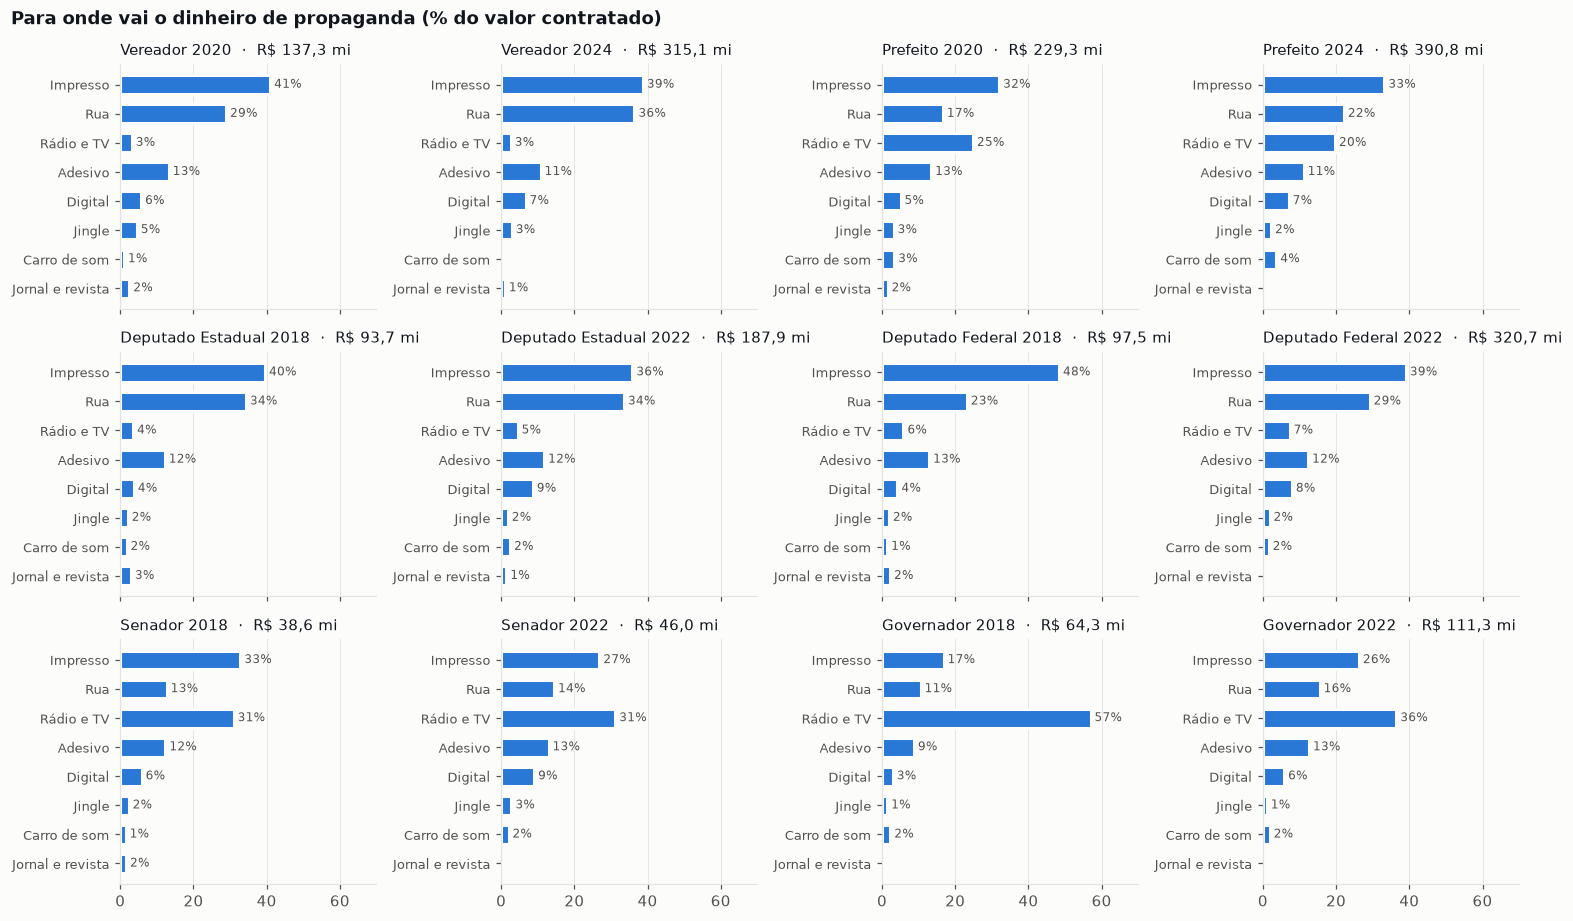

In [13]:
fig, eixos = plt.subplots(3, 4, figsize=(14, 8.5), sharex=True)
for ax, (cargo, ano) in zip(eixos.flat, PAINEIS, strict=True):
    d = tot[(tot.ano == ano) & (tot.ds_cargo == cargo)].set_index("ds_canal").reindex(CANAIS).fillna(0)
    y = np.arange(len(CANAIS))[::-1]
    ax.barh(y, d.pc, height=0.65, color=SERIE, edgecolor=SUPERFICIE, linewidth=2)
    for yi, pc, _vr in zip(y, d.pc, d.vr_despesa, strict=True):
        if pc >= 1:
            ax.text(pc, yi, f" {pc:.0f}%", va="center", fontsize=8, color=TEXTO_2)
    total = d.vr_despesa.sum() / 1e6
    ax.set_title(
        f"{cargo.title()} {ano}  ·  R$ {total:,.1f} mi".replace(",", "X").replace(".", ",").replace("X", "."),
        loc="left",
        fontsize=10,
    )
    ax.set_yticks(y, [CANAL_NOME[c] for c in CANAIS], fontsize=8.5)
    ax.set_xlim(0, 70)
    ax.grid(axis="x", color=GRADE, lw=0.6)
    ax.set_axisbelow(True)
fig.suptitle("Para onde vai o dinheiro de propaganda (% do valor contratado)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(SAIDA / "q9_a_canal.png", bbox_inches="tight")
plt.show()

**Como ler:** cada painel soma 100% do valor contratado em propaganda naquele cargo e ano; o título traz o total.

- **Impresso** (santinho, panfleto, praguinha) e **rua** (cabo eleitoral, militância, eventos) são o grosso do dinheiro em vereador, prefeito e deputados.
- **Rádio e TV** lidera nas majoritárias estaduais (governador 2018: 57%; senador: 31%) e pesa em prefeito (20% a 25%).
- **Digital** cresce de 2018 para 2022 e de 2020 para 2024, mas segue pequeno no valor.

## B. Eleitos e não eleitos investem diferente?

A mesma divisão por canal, separando quem se elegeu. Se a "receita" da propaganda importasse, os eleitos teriam uma divisão diferente.

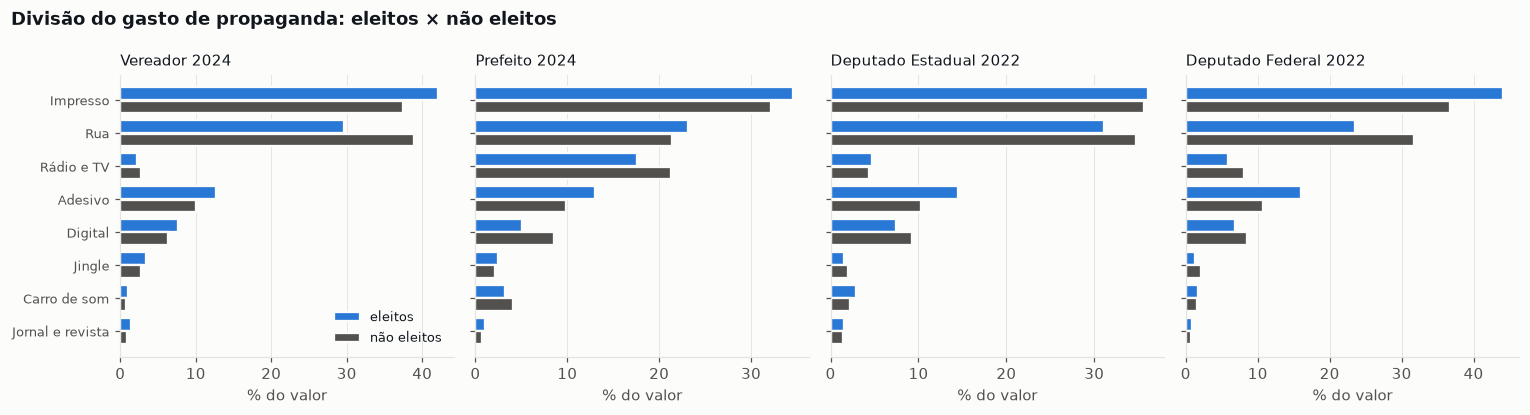

In [14]:
el = canal.groupby(["ano", "ds_cargo", "fl_eleito", "ds_canal"], as_index=False)["vr_despesa"].sum()
el["pc"] = 100 * el.vr_despesa / el.groupby(["ano", "ds_cargo", "fl_eleito"]).vr_despesa.transform("sum")

PAINEIS_B = [("VEREADOR", 2024), ("PREFEITO", 2024), ("DEPUTADO ESTADUAL", 2022), ("DEPUTADO FEDERAL", 2022)]
fig, eixos = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, (cargo, ano) in zip(eixos, PAINEIS_B, strict=True):
    y = np.arange(len(CANAIS))[::-1]
    for desl, flag, cor, nome in [(0.2, True, PUBLICO, "eleitos"), (-0.2, False, TEXTO_2, "não eleitos")]:
        d = el[(el.ano == ano) & (el.ds_cargo == cargo) & (el.fl_eleito == flag)].set_index("ds_canal").reindex(CANAIS)
        ax.barh(y + desl, d.pc.fillna(0), height=0.38, color=cor, edgecolor=SUPERFICIE, linewidth=1.5, label=nome)
    ax.set_yticks(y, [CANAL_NOME[c] for c in CANAIS], fontsize=8.5)
    ax.set_title(f"{cargo.title()} {ano}", loc="left", fontsize=10)
    ax.grid(axis="x", color=GRADE, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_xlabel("% do valor")
eixos[0].legend(frameon=False, fontsize=8.5, loc="lower right")
fig.suptitle("Divisão do gasto de propaganda: eleitos × não eleitos", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(SAIDA / "q9_b_eleitos.png", bbox_inches="tight")
plt.show()

In [15]:
# gasto mediano em propaganda por candidato que gastou algo: a diferença está no QUANTO, não no ONDE
sql("""
    WITH c AS (
        SELECT ano, ds_cargo, fl_eleito, sq_candidato, sum(vr_despesa) AS vr
        FROM mart_q9 WHERE fl_divulgado GROUP BY ALL
    )
    SELECT ano, ds_cargo,
           round(median(vr) FILTER (WHERE fl_eleito)) AS mediana_eleitos,
           round(median(vr) FILTER (WHERE NOT fl_eleito)) AS mediana_nao_eleitos
    FROM c WHERE ds_cargo IN ('VEREADOR', 'PREFEITO', 'DEPUTADO ESTADUAL', 'DEPUTADO FEDERAL')
    GROUP BY ALL ORDER BY ds_cargo, ano
""")

,ano,ds_cargo,mediana_eleitos,mediana_nao_eleitos
0,2018,DEPUTADO ESTADUAL,112749.0,7460.0
1,2022,DEPUTADO ESTADUAL,230592.0,18790.0
2,2018,DEPUTADO FEDERAL,412361.0,10332.0
3,2022,DEPUTADO FEDERAL,1082829.0,40903.0
4,2020,PREFEITO,30062.0,18440.0
5,2024,PREFEITO,61724.0,39685.0
6,2020,VEREADOR,1295.0,962.0
7,2024,VEREADOR,2500.0,2000.0


**Como ler:** compare as duas barras de cada canal.

- A ordem dos canais é a mesma para eleitos e não eleitos, mas em vereador e deputados há um padrão: **os eleitos põem uma fatia maior em adesivo e impresso e menor em rua** (vereador 2024: rua é 29,6% do gasto dos eleitos e 39,0% dos não eleitos; deputado federal 2022: 23,5% × 31,7%). Rua é sobretudo cabo eleitoral: a campanha pequena é, proporcionalmente, mais gente e menos material. Em prefeito, não: os eleitos põem um pouco mais em rua e menos em rádio e TV.
- A diferença maior está no **quanto** (tabela acima). O deputado federal eleito em 2022 gastou em propaganda, em mediana, R$ 1,08 milhão; o não eleito, R$ 41 mil (26 vezes menos). Em vereador a distância é pequena: R$ 2.500 × R$ 2.000 em 2024.

## C. Nuvem de palavras do texto livre

O tamanho da palavra é o número de despesas que a citam. O texto foi limpo no SQL (`q9_termo`): sem acento, expressões como "cabo eleitoral" e "carro de som" juntas, plural no singular, e sem palavras que não dizem *onde* se investiu ("serviço", "campanha", "prestação", o nome do cargo).

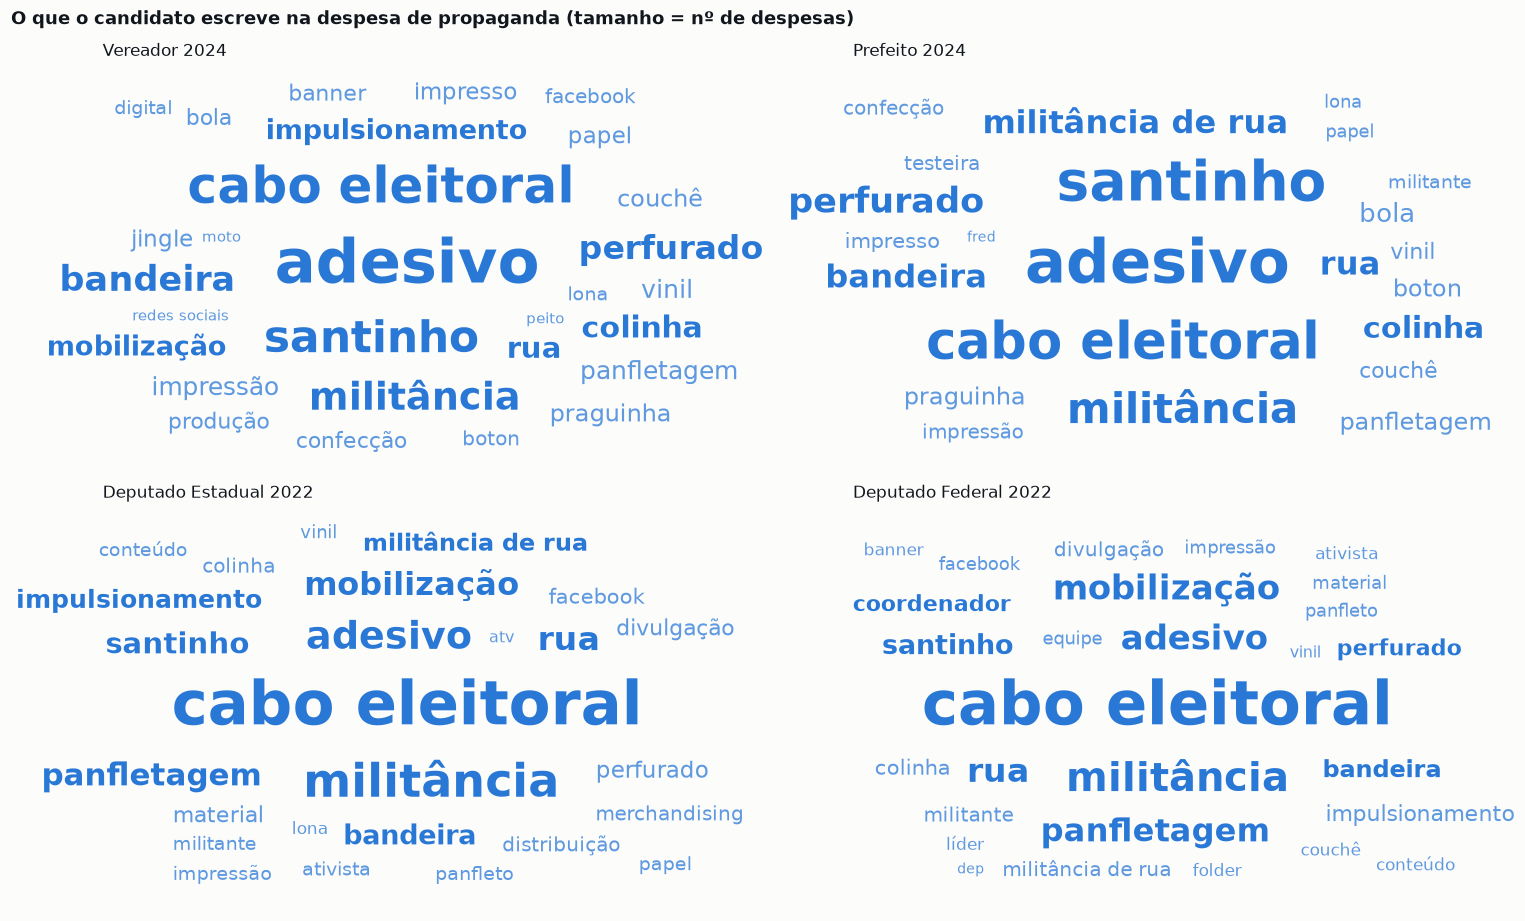

In [16]:
def nuvem(ax, termos: pd.Series, cor=SERIE, maximo=60, tam=(9, 40)):
    """Nuvem de palavras sem biblioteca externa: espiral de Arquimedes a partir do centro.

    termos: Série termo → peso (já ordenada do maior ao menor).
    """
    termos = termos.head(maximo)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    ocupadas = []
    pmax, pmin = termos.iloc[0], termos.iloc[-1]
    for i, (termo, peso) in enumerate(termos.items()):
        t = (np.sqrt(peso) - np.sqrt(pmin)) / max(np.sqrt(pmax) - np.sqrt(pmin), 1e-9)
        fs = tam[0] + t * (tam[1] - tam[0])
        alfa = 1.0 if i < 10 else 0.75
        txt = ax.text(
            0.5,
            0.5,
            termo,
            fontsize=fs,
            ha="center",
            va="center",
            color=cor,
            alpha=alfa,
            fontweight="bold" if i < 10 else "normal",
        )
        for passo in range(4000):
            ang = 0.35 * passo
            raio = 0.0016 * ang
            x, y = 0.5 + raio * np.cos(ang) * 1.5, 0.5 + raio * np.sin(ang)
            if not (0.05 < x < 0.95 and 0.06 < y < 0.94):
                continue
            txt.set_position((x, y))
            bb = txt.get_window_extent(rend).expanded(1.04, 1.12)
            if not any(bb.overlaps(o) for o in ocupadas):
                ocupadas.append(bb)
                break
        else:
            txt.remove()


termo = sql("SELECT * FROM q9_termo")
fig, eixos = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, (cargo, ano) in zip(eixos.flat, PAINEIS_B, strict=True):
    t = termo[(termo.ano == ano) & (termo.ds_cargo == cargo)].groupby("ds_termo").qt_despesas.sum()
    nuvem(ax, t.sort_values(ascending=False))
    ax.set_title(f"{cargo.title()} {ano}", loc="left", fontsize=11)
fig.suptitle(
    "O que o candidato escreve na despesa de propaganda (tamanho = nº de despesas)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(SAIDA / "q9_c_nuvem.png", bbox_inches="tight")
plt.show()

### Frequência × valor

A nuvem não mostra dinheiro: "cabo eleitoral" aparece em muitas despesas pequenas, "rádio" e "tv" em poucas e caras. A tabela traz, para os 25 termos mais citados (vereador 2024), quantas despesas os citam e o **valor das despesas** que os citam.

⚠️ Uma despesa que cita três termos entra nos três, então o valor **não soma entre termos**. O total por canal está na parte A.

In [17]:
t = (
    termo[(termo.ano == 2024) & (termo.ds_cargo == "VEREADOR")]
    .groupby("ds_termo")[["qt_despesas", "vr_despesa"]]
    .sum()
    .sort_values("qt_despesas", ascending=False)
    .head(25)
)
t["valor médio (R$)"] = (t.vr_despesa / t.qt_despesas).round(0)
t["vr_despesa"] = (t.vr_despesa / 1e6).round(2)
t.rename(columns={"qt_despesas": "despesas", "vr_despesa": "valor (R$ mi)"})

,despesas,valor (R$ mi),valor médio (R$)
ds_termo,,,
adesivo,80634,41.38,513.0
cabo eleitoral,52165,46.62,894.0
santinho,37865,30.87,815.0
militância,28088,25.14,895.0
bandeira,22659,17.44,770.0
perfurado,19492,12.37,635.0
colinha,15221,7.73,508.0
rua,14559,12.12,832.0
impulsionamento,12527,13.12,1047.0


In [18]:
# os termos mais "caros": maior valor médio por despesa, entre os citados em ao menos 200 despesas.
# É onde aparecem rádio, TV e marketing: poucas despesas, valor alto.
caro = termo.groupby("ds_termo")[["qt_despesas", "vr_despesa"]].sum()
caro = caro[caro.qt_despesas >= 200].assign(medio=lambda d: d.vr_despesa / d.qt_despesas)
caro.sort_values("medio", ascending=False).head(15).round(0)

,qt_despesas,vr_despesa,medio
ds_termo,,,
consultoria,209,8067158.0,38599.0
direção,202,6357148.0,31471.0
televisão,247,5622065.0,22761.0
programa,2619,59035559.0,22541.0
equipamento,229,5080675.0,22186.0
planejamento,229,4884927.0,21332.0
prog,438,9215114.0,21039.0
marketing,2545,48352854.0,18999.0
rádio,3237,58979286.0,18220.0


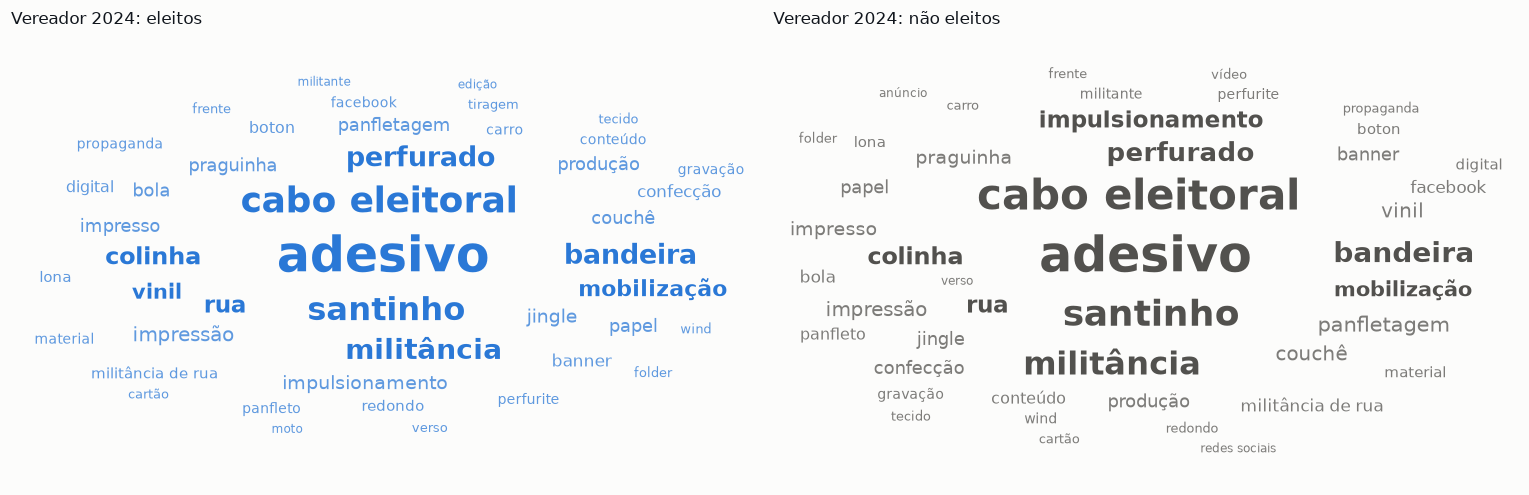

In [19]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (flag, nome) in zip(eixos, [(True, "eleitos"), (False, "não eleitos")], strict=True):
    t = termo[(termo.ano == 2024) & (termo.ds_cargo == "VEREADOR") & (termo.fl_eleito == flag)]
    nuvem(
        ax,
        t.groupby("ds_termo").qt_despesas.sum().sort_values(ascending=False),
        cor=PUBLICO if flag else TEXTO_2,
        maximo=45,
        tam=(8, 32),
    )
    ax.set_title(f"Vereador 2024: {nome}", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(SAIDA / "q9_c_nuvem_eleitos.png", bbox_inches="tight")
plt.show()

**Como ler:** as palavras grandes são as mesmas para eleitos e não eleitos: **adesivo, cabo eleitoral, santinho, militância, bandeira**. A campanha típica é material impresso barato e gente na rua. "Impulsionamento" e "facebook" aparecem, mas bem menores.

**O que a nuvem não mostra:** valor (ver a tabela e a parte A) nem o canal de quem não escreveu nada útil na descrição. O texto é livre: o mesmo serviço aparece como "militância", "mobilização de rua" ou "ativista", e a limpeza junta só plural e acento.